# 🧪 Text-to-Image Diffusion from Scratch

This notebook builds a small text-to-image diffusion model and trains it from random weights on Fashion-MNIST: 70,000 greyscale clothing images, 28×28 pixels, in 10 categories. Unlike the Stable Diffusion project in this repository, no pre-trained image model is used. The noise schedule, the U-Net, the training loop and the sampler are all written here in PyTorch.

Prompts are turned into numbers by CLIP, a pre-trained text encoder that stays frozen. The model can only draw the 10 categories in the dataset, but it accepts different wordings for them, such as "a sneaker" or "a white running shoe".

**To run:** *Runtime → Change runtime type → T4 GPU*, then *Runtime → Run all*. Tick `QUICK_CHECK` in Settings for a 2–3 minute test of every cell first.

**Time on a T4:** about 12 minutes with the default settings, of which about 10 minutes is training.

The saved output of the cell that displays Fashion-MNIST's training images is cleared. Running the notebook shows it.

In [1]:
#@title ⚙️ Settings
QUICK_CHECK = False       #@param {type:"boolean"}
# Tick for a 2-3 minute run that checks every cell works. Its images will still look like noise.

EPOCHS = 20               #@param {type:"integer"}
GUIDANCE_SCALE = 3.0      #@param {type:"number"}
SAMPLING_STEPS = 50       #@param {type:"integer"}
SEED = 1337               #@param {type:"integer"}
SAVE_TO_DRIVE = True      #@param {type:"boolean"}

BATCH_SIZE = 128
LEARNING_RATE = 2e-4
TIMESTEPS = 1000          # noise levels the model learns to remove
DROP_PROMPT = 0.1         # share of training images shown without a prompt, which guidance needs
BASE_CHANNELS = 64        # width of the U-Net
TEXT_MODEL = "openai/clip-vit-base-patch32"   # frozen text encoder: only the image model is trained here
WORK_DIR = "/content/diffusion_from_scratch"
DRIVE_DIR = "/content/drive/MyDrive/diffusion_from_scratch"

TRAIN_IMAGES, EVAL_IMAGES_PER_PROMPT = (6000, 10) if QUICK_CHECK else (60000, 100)
if QUICK_CHECK:
    EPOCHS = 1
print(f"{'Quick check' if QUICK_CHECK else 'Full run'}: {TRAIN_IMAGES} images, {EPOCHS} epochs")

Full run: 60000 images, 20 epochs


In [2]:
#@title 🔧 Setup: GPU, Google Drive and folders
import copy
import math
import time
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

if torch.cuda.is_available():
    DEVICE = "cuda"
    torch.backends.cudnn.benchmark = True
    print("GPU:", torch.cuda.get_device_name(0))
else:
    DEVICE = "cpu"
    print("No GPU found: this will be very slow. Choose Runtime > Change runtime type > T4 GPU.")
USE_AMP = DEVICE == "cuda"   # mixed precision is faster on a T4
torch.manual_seed(SEED)

WORK = Path(WORK_DIR)
WORK.mkdir(parents=True, exist_ok=True)

SAVE_DIR = None
if SAVE_TO_DRIVE:
    from google.colab import drive
    try:
        drive.mount("/content/drive")
    except Exception as error:
        # Drive is only a backup, so a refused mount should not stop the run.
        print(f"Google Drive not mounted ({error}). Continuing: the model stays in {WORK_DIR} until this runtime ends.")
    else:
        SAVE_DIR = Path(DRIVE_DIR)
        SAVE_DIR.mkdir(parents=True, exist_ok=True)
        print("The trained model will also be copied to:", SAVE_DIR)


def show_grid(images, rows, cols, row_titles=None, col_titles=None, title=None, size=1.1):
    # Draw images (values from -1 to 1) in a grid, filling one row at a time.
    fig, axes = plt.subplots(rows, cols, figsize=(cols * size + (2.4 if row_titles else 0), rows * size), squeeze=False)
    for i, ax in enumerate(axes.flatten()):
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
        if i < len(images):
            ax.imshow(images[i, 0].float().cpu(), cmap="gray", vmin=-1, vmax=1)
    for r, text in enumerate(row_titles or []):
        axes[r][0].set_ylabel(text, rotation=0, ha="right", va="center", fontsize=9)
    for c, text in enumerate(col_titles or []):
        axes[0][c].set_title(text, fontsize=9)
    if title:
        fig.suptitle(title)
    plt.tight_layout()
    plt.show()

GPU: Tesla T4
Mounted at /content/drive
The trained model will also be copied to: /content/drive/MyDrive/diffusion_from_scratch


## 1. Data

Fashion-MNIST has 60,000 training images and 10,000 test images. They are small enough to keep on the GPU, which makes training faster than reading them from disk. Pixel values are scaled from 0–255 to −1–1, the range the noise is added in.

In [3]:
#@title 📚 Load Fashion-MNIST
from torchvision import datasets

train_set = datasets.FashionMNIST(str(WORK / "data"), train=True, download=True)
test_set = datasets.FashionMNIST(str(WORK / "data"), train=False, download=True)
CLASS_NAMES = train_set.classes


def to_model_range(pixels):
    # 28x28 images with values 0-255 become 1x28x28 tensors with values -1 to 1.
    return pixels.float().div(127.5).sub(1).unsqueeze(1)


order = torch.randperm(len(train_set), generator=torch.Generator().manual_seed(SEED))[:TRAIN_IMAGES]
train_images = to_model_range(train_set.data[order]).to(DEVICE)
train_labels = train_set.targets[order].to(DEVICE)
test_images = to_model_range(test_set.data).to(DEVICE)
test_labels = test_set.targets.to(DEVICE)
print(f"Training images: {len(train_images)} | test images: {len(test_images)}")

examples = torch.cat([train_images[train_labels == c][:8] for c in range(10)])
show_grid(examples, 10, 8, row_titles=CLASS_NAMES, title="Training images, one row per category")

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.7MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 201kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.76MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 23.3MB/s]


Training images: 60000 | test images: 10000


## 2. Text prompts

CLIP turns each prompt into a list of 512 numbers. During training, every image is paired with a random wording of its category, such as "a picture of a jumper" for a pullover, so the model learns to accept different phrasing.

The test prompts below use wordings the model never sees in training. The notebook also measures how close each prompt is to the 10 categories, so it can tell when a prompt asks for something the model has not learned, such as "a cat".

In [4]:
#@title 💬 Turn prompts into numbers with CLIP
from transformers import CLIPTextModelWithProjection, CLIPTokenizer
from transformers.utils import logging as transformers_logging

# Loading only CLIP's text half lists every unused image weight. That report is expected, so it is hidden.
transformers_logging.set_verbosity_error()

# Words for each category, in the dataset's order.
WORDS = [
    ["t-shirt", "top", "tee"],
    ["pair of trousers", "pair of pants", "pair of jeans"],
    ["pullover", "sweater", "jumper"],
    ["dress", "summer dress"],
    ["coat", "jacket", "winter coat"],
    ["sandal", "summer sandal"],
    ["shirt", "button-up shirt"],
    ["sneaker", "trainer", "running shoe"],
    ["bag", "handbag"],
    ["ankle boot", "boot"],
]
TRAIN_TEMPLATES = ["a {}", "a photo of a {}", "a picture of a {}", "an image of a {}",
                   "a black and white photo of a {}", "a small photo of a {}"]
# One new wording per category, never used in training.
TEST_PROMPTS = ["a short-sleeved t-shirt", "a pair of long trousers", "a warm woollen sweater",
                "an elegant evening dress", "a long winter coat", "an open-toed sandal", "a collared shirt",
                "a white running shoe", "a leather handbag", "a leather ankle boot"]
OFF_TOPIC = ["a cat", "a red sports car", "a bowl of soup", "a mountain at sunset", "a guitar", "a bicycle"]

tokenizer = CLIPTokenizer.from_pretrained(TEXT_MODEL)
text_encoder = CLIPTextModelWithProjection.from_pretrained(TEXT_MODEL).to(DEVICE).eval()


@torch.no_grad()
def encode(texts):
    tokens = tokenizer(list(texts), padding=True, return_tensors="pt").to(DEVICE)
    return F.normalize(text_encoder(**tokens).text_embeds.float(), dim=-1)


train_prompts = [[template.format(word) for word in WORDS[c] for template in TRAIN_TEMPLATES] for c in range(10)]
assert not set(TEST_PROMPTS) & {p for prompts in train_prompts for p in prompts}, "test prompts must be new wordings"
class_embeddings = [encode(prompts) for prompts in train_prompts]
TEXT_DIM = class_embeddings[0].shape[1]

# A table of every training prompt's numbers, padded to the same length per category.
prompt_counts = torch.tensor([len(e) for e in class_embeddings], device=DEVICE)
prompt_bank = torch.zeros(10, int(prompt_counts.max()), TEXT_DIM, device=DEVICE)
for c, e in enumerate(class_embeddings):
    prompt_bank[c, : len(e)] = e
centroids = F.normalize(torch.stack([e.mean(0) for e in class_embeddings]), dim=-1)


def closest_category(texts):
    similarity = encode(texts) @ centroids.T
    return similarity.max(dim=1)


# The threshold for "a category this model knows" sits halfway between new wordings and off-topic prompts.
test_score, test_match = closest_category(TEST_PROMPTS)
off_score, off_match = closest_category(OFF_TOPIC)
KNOWN_THRESHOLD = float((test_score.min() + off_score.max()) / 2)

print(f"{sum(len(p) for p in train_prompts)} training prompts. Closest category for the new wordings:")
for text, score, match, expected in zip(TEST_PROMPTS, test_score, test_match, CLASS_NAMES):
    print(f"  {text!r:28} → {CLASS_NAMES[match]:12} similarity {score:.3f} {'' if CLASS_NAMES[match] == expected else '(expected ' + expected + ')'}")
print("Off-topic prompts:")
for text, score, match in zip(OFF_TOPIC, off_score, off_match):
    print(f"  {text!r:28} → closest is {CLASS_NAMES[match]:12} similarity {score:.3f}")
print(f"Threshold for a known category: {KNOWN_THRESHOLD:.3f}")
if test_score.min() <= off_score.max():
    print("Warning: some off-topic prompts score as high as real ones, so the threshold cannot separate them all.")

150 training prompts. Closest category for the new wordings:
  'a short-sleeved t-shirt'    → T-shirt/top  similarity 0.915
  'a pair of long trousers'    → Trouser      similarity 0.926
  'a warm woollen sweater'     → Pullover     similarity 0.903
  'an elegant evening dress'   → Dress        similarity 0.878
  'a long winter coat'         → Coat         similarity 0.919
  'an open-toed sandal'        → Sandal       similarity 0.946
  'a collared shirt'           → Shirt        similarity 0.920
  'a white running shoe'       → Sneaker      similarity 0.904
  'a leather handbag'          → Bag          similarity 0.917
  'a leather ankle boot'       → Ankle boot   similarity 0.897
Off-topic prompts:
  'a cat'                      → closest is Sneaker      similarity 0.854
  'a red sports car'           → closest is Sneaker      similarity 0.724
  'a bowl of soup'             → closest is T-shirt/top  similarity 0.824
  'a mountain at sunset'       → closest is T-shirt/top  similarity 

## 3. The model and the noise

**Noise schedule:** 1,000 noise levels, from almost clean to pure noise. `add_noise` jumps straight to any level in one step.

**U-Net:** the network that predicts the noise. It shrinks the image from 28×28 to 14×14 to 7×7 and back, with shortcuts between matching sizes, and looks across the whole image at 7×7. Two extra inputs steer every layer: the noise level and the prompt.

**Sampler:** starts from pure noise and removes it in 50 steps (the DDIM method). At each step it predicts the noise twice, with and without the prompt, and moves further towards the prompt. This is classifier-free guidance, and `GUIDANCE_SCALE` sets how far.

In [5]:
#@title 🧱 Build the noise schedule, the U-Net and the sampler
betas = torch.linspace(1e-4, 0.02, TIMESTEPS, device=DEVICE)
alpha_bars = torch.cumprod(1 - betas, dim=0)   # how much of the clean image survives at each level


def add_noise(clean, t, noise):
    a = alpha_bars[t].view(-1, 1, 1, 1)
    return a.sqrt() * clean + (1 - a).sqrt() * noise


def timestep_embedding(t, dim):
    # Turns each noise level into a list of sine and cosine values, so nearby levels look similar.
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / half)
    angles = t.float()[:, None] * freqs[None]
    return torch.cat([angles.sin(), angles.cos()], dim=1)


class ResBlock(nn.Module):
    def __init__(self, channels_in, channels_out, emb_dim):
        super().__init__()
        self.norm1 = nn.GroupNorm(8, channels_in)
        self.conv1 = nn.Conv2d(channels_in, channels_out, 3, padding=1)
        self.emb = nn.Linear(emb_dim, channels_out)
        self.norm2 = nn.GroupNorm(8, channels_out)
        self.conv2 = nn.Conv2d(channels_out, channels_out, 3, padding=1)
        self.skip = nn.Conv2d(channels_in, channels_out, 1) if channels_in != channels_out else nn.Identity()

    def forward(self, x, emb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.emb(emb)[:, :, None, None]   # the noise level and prompt steer this block
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)


class SelfAttention(nn.Module):
    def __init__(self, channels, heads=4):
        super().__init__()
        self.norm = nn.GroupNorm(8, channels)
        self.attn = nn.MultiheadAttention(channels, heads, batch_first=True)

    def forward(self, x):
        b, c, h, w = x.shape
        tokens = self.norm(x).flatten(2).transpose(1, 2)
        out, _ = self.attn(tokens, tokens, tokens, need_weights=False)
        return x + out.transpose(1, 2).reshape(b, c, h, w)


class UNet(nn.Module):
    def __init__(self, ch, text_dim):
        super().__init__()
        emb = ch * 4
        self.ch = ch
        self.time_mlp = nn.Sequential(nn.Linear(ch, emb), nn.SiLU(), nn.Linear(emb, emb))
        self.text_mlp = nn.Sequential(nn.Linear(text_dim, emb), nn.SiLU(), nn.Linear(emb, emb))
        self.null_text = nn.Parameter(torch.zeros(text_dim))   # stands in for "no prompt"
        self.inc = nn.Conv2d(1, ch, 3, padding=1)
        self.down1 = ResBlock(ch, ch, emb)                                # 28x28
        self.shrink1 = nn.Conv2d(ch, ch, 3, stride=2, padding=1)          # to 14x14
        self.down2 = ResBlock(ch, ch * 2, emb)                            # 14x14
        self.shrink2 = nn.Conv2d(ch * 2, ch * 2, 3, stride=2, padding=1)  # to 7x7
        self.mid1 = ResBlock(ch * 2, ch * 4, emb)                         # 7x7
        self.attn = SelfAttention(ch * 4)
        self.mid2 = ResBlock(ch * 4, ch * 2, emb)
        self.up2 = ResBlock(ch * 4, ch, emb)                              # 14x14, after joining down2's output
        self.up1 = ResBlock(ch * 2, ch, emb)                              # 28x28, after joining down1's output
        self.out = nn.Sequential(nn.GroupNorm(8, ch), nn.SiLU(), nn.Conv2d(ch, 1, 3, padding=1))

    def forward(self, x, t, text, use_prompt):
        text = torch.where(use_prompt[:, None], text, self.null_text.to(text.dtype).expand_as(text))
        emb = self.time_mlp(timestep_embedding(t, self.ch)) + self.text_mlp(text)
        h1 = self.down1(self.inc(x), emb)
        h2 = self.down2(self.shrink1(h1), emb)
        h = self.mid2(self.attn(self.mid1(self.shrink2(h2), emb)), emb)
        h = self.up2(torch.cat([F.interpolate(h, scale_factor=2.0, mode="nearest"), h2], dim=1), emb)
        h = self.up1(torch.cat([F.interpolate(h, scale_factor=2.0, mode="nearest"), h1], dim=1), emb)
        return self.out(h)


@torch.no_grad()
def generate(prompts, per_prompt=8, guidance=GUIDANCE_SCALE, steps=SAMPLING_STEPS, seed=SEED, net=None, record=None):
    # Draws per_prompt images for each prompt, starting from seeded noise.
    net = ema if net is None else net
    net.eval()
    text = encode(prompts).repeat_interleave(per_prompt, dim=0)
    n = len(text)
    x = torch.randn(n, 1, 28, 28, generator=torch.Generator(device=DEVICE).manual_seed(seed), device=DEVICE)
    both_text = torch.cat([text, text])
    use_prompt = torch.cat([torch.ones(n, dtype=torch.bool, device=DEVICE), torch.zeros(n, dtype=torch.bool, device=DEVICE)])
    times = torch.linspace(TIMESTEPS - 1, 0, steps, device=DEVICE).round().long()
    if record is not None:
        record.append(x.clone())
    for i, t in enumerate(times):
        with torch.autocast(device_type=DEVICE, dtype=torch.float16, enabled=USE_AMP):
            out = net(torch.cat([x, x]), t.repeat(2 * n), both_text, use_prompt).float()
        with_prompt, without_prompt = out.chunk(2)
        noise = without_prompt + guidance * (with_prompt - without_prompt)
        a = alpha_bars[t]
        a_next = alpha_bars[times[i + 1]] if i + 1 < len(times) else torch.ones((), device=DEVICE)
        clean = ((x - (1 - a).sqrt() * noise) / a.sqrt()).clamp(-1, 1)
        noise = (x - a.sqrt() * clean) / (1 - a).sqrt()
        x = a_next.sqrt() * clean + (1 - a_next).sqrt() * noise
        if record is not None:
            record.append(x.clone())
    return x.clamp(-1, 1)


model = UNet(BASE_CHANNELS, TEXT_DIM).to(DEVICE)
ema = copy.deepcopy(model).eval().requires_grad_(False)   # a smoothed copy of the weights, used for drawing
print(f"U-Net parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.1f} million")

U-Net parameters: 2.9 million


## 4. Training from scratch

Each step takes a batch of clothing images, picks a random noise level for each one, adds that much noise, and asks the U-Net to predict the noise from the noisy image, the noise level and a prompt. The loss is the difference between the predicted and the real noise. One image in ten is shown without its prompt, so the model also learns to draw without one, which guidance needs.

A smoothed copy of the weights (EMA) is kept alongside the model and used for drawing, because it gives cleaner images than the weights at any single step. A preview row is drawn a few times during training.

epoch 1/20  loss 0.1738  11.5 steps per second  about 12.9 min of training left
epoch 2/20  loss 0.0543  16.9 steps per second  about 10.3 min of training left
epoch 3/20  loss 0.0473  16.7 steps per second  about 9.1 min of training left
epoch 4/20  loss 0.0445  16.9 steps per second  about 8.3 min of training left
epoch 5/20  loss 0.0441  16.8 steps per second  about 7.6 min of training left


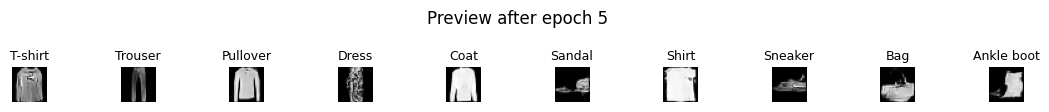

epoch 6/20  loss 0.0425  16.8 steps per second  about 7.0 min of training left
epoch 7/20  loss 0.0416  16.9 steps per second  about 6.4 min of training left
epoch 8/20  loss 0.0405  16.8 steps per second  about 5.9 min of training left
epoch 9/20  loss 0.0400  16.8 steps per second  about 5.4 min of training left
epoch 10/20  loss 0.0395  16.8 steps per second  about 4.9 min of training left


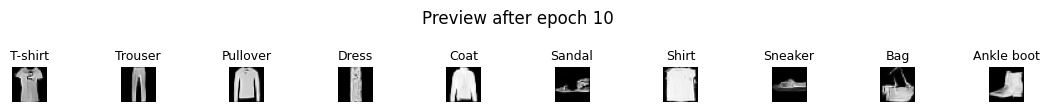

epoch 11/20  loss 0.0390  16.8 steps per second  about 4.4 min of training left
epoch 12/20  loss 0.0384  16.9 steps per second  about 3.9 min of training left
epoch 13/20  loss 0.0387  16.8 steps per second  about 3.4 min of training left
epoch 14/20  loss 0.0386  16.8 steps per second  about 2.9 min of training left
epoch 15/20  loss 0.0375  16.8 steps per second  about 2.4 min of training left


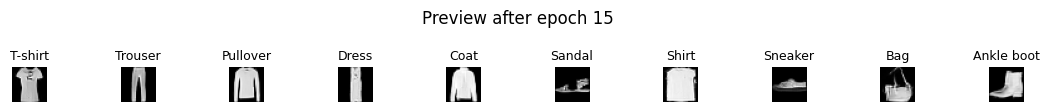

epoch 16/20  loss 0.0373  16.9 steps per second  about 1.9 min of training left
epoch 17/20  loss 0.0379  16.9 steps per second  about 1.4 min of training left
epoch 18/20  loss 0.0370  16.9 steps per second  about 1.0 min of training left
epoch 19/20  loss 0.0373  16.9 steps per second  about 0.5 min of training left
epoch 20/20  loss 0.0373  15.7 steps per second  about 0.0 min of training left


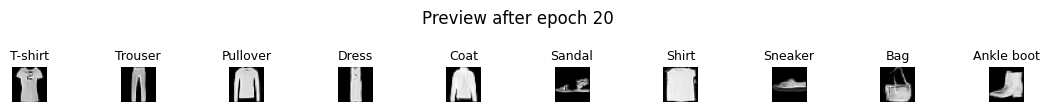

Training took 9.5 minutes, not counting previews (16.4 steps per second). The first epoch is slower while the GPU warms up.


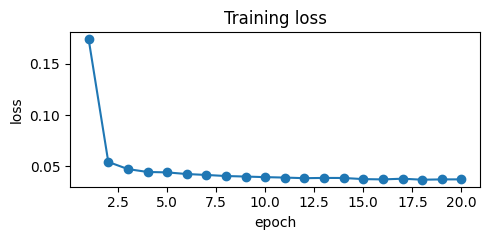

In [6]:
#@title 🚀 Train the model
import warnings

# The mixed-precision scaler skips its first few steps while it calibrates, which triggers a harmless warning.
warnings.filterwarnings("ignore", message="Detected call of `lr_scheduler.step")
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
steps_per_epoch = math.ceil(len(train_images) / BATCH_SIZE)
total_steps = EPOCHS * steps_per_epoch
warmup = max(1, min(500, total_steps // 10))
schedule = torch.optim.lr_scheduler.LambdaLR(
    optimizer, lambda s: min(1.0, (s + 1) / warmup) * 0.5 * (1 + math.cos(math.pi * min(s, total_steps) / total_steps)))
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)


@torch.no_grad()
def update_ema(step):
    decay = min(0.999, (1 + step) / (10 + step))
    for e, p in zip(ema.parameters(), model.parameters()):
        e.lerp_(p, 1 - decay)


preview_every = max(1, EPOCHS // 4)
losses, step, train_seconds = [], 0, 0.0
for epoch in range(1, EPOCHS + 1):
    model.train()
    epoch_start = time.time()
    epoch_loss = torch.zeros((), device=DEVICE)
    for idx in torch.randperm(len(train_images), device=DEVICE).split(BATCH_SIZE):
        clean, labels = train_images[idx], train_labels[idx]
        pick = (torch.rand(len(idx), device=DEVICE) * prompt_counts[labels]).long()   # a random wording
        text = prompt_bank[labels, pick]
        use_prompt = torch.rand(len(idx), device=DEVICE) >= DROP_PROMPT
        t = torch.randint(0, TIMESTEPS, (len(idx),), device=DEVICE)
        noise = torch.randn_like(clean)
        with torch.autocast(device_type=DEVICE, dtype=torch.float16, enabled=USE_AMP):
            loss = F.mse_loss(model(add_noise(clean, t, noise), t, text, use_prompt).float(), noise)
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()
        schedule.step()
        update_ema(step)
        step += 1
        epoch_loss += loss.detach()
    losses.append(epoch_loss.item() / steps_per_epoch)   # .item() also waits for the GPU to finish
    epoch_seconds = time.time() - epoch_start
    train_seconds += epoch_seconds
    print(f"epoch {epoch}/{EPOCHS}  loss {losses[-1]:.4f}  {steps_per_epoch / epoch_seconds:.1f} steps per second  "
          f"about {train_seconds / epoch * (EPOCHS - epoch) / 60:.1f} min of training left")
    if epoch % preview_every == 0 or epoch == EPOCHS:
        show_grid(generate(TEST_PROMPTS, per_prompt=1, steps=25), 1, 10,
                  col_titles=[name.split("/")[0] for name in CLASS_NAMES], title=f"Preview after epoch {epoch}")

print(f"Training took {train_seconds / 60:.1f} minutes, not counting previews ({step / train_seconds:.1f} steps per second). "
      "The first epoch is slower while the GPU warms up.")
plt.figure(figsize=(5, 2.5))
plt.plot(range(1, EPOCHS + 1), losses, marker="o")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.title("Training loss")
plt.tight_layout()
plt.show()

In [7]:
#@title 💾 Save the trained model
checkpoint = {"ema": ema.state_dict(), "base_channels": BASE_CHANNELS, "text_dim": TEXT_DIM,
              "timesteps": TIMESTEPS, "text_model": TEXT_MODEL, "class_names": CLASS_NAMES}
MODEL_FILE = WORK / "diffusion_from_scratch.pt"
torch.save(checkpoint, MODEL_FILE)
print(f"Model saved: {MODEL_FILE} ({MODEL_FILE.stat().st_size / 1024 / 1024:.1f} MB)")
if SAVE_DIR:
    torch.save(checkpoint, SAVE_DIR / MODEL_FILE.name)
    print("Copied to:", SAVE_DIR / MODEL_FILE.name)

Model saved: /content/diffusion_from_scratch/diffusion_from_scratch.pt (11.2 MB)
Copied to: /content/drive/MyDrive/diffusion_from_scratch/diffusion_from_scratch.pt


## 5. Results

### Text to image with new wordings

Each row is one prompt the model never saw in training, with 8 images from different starting noise.

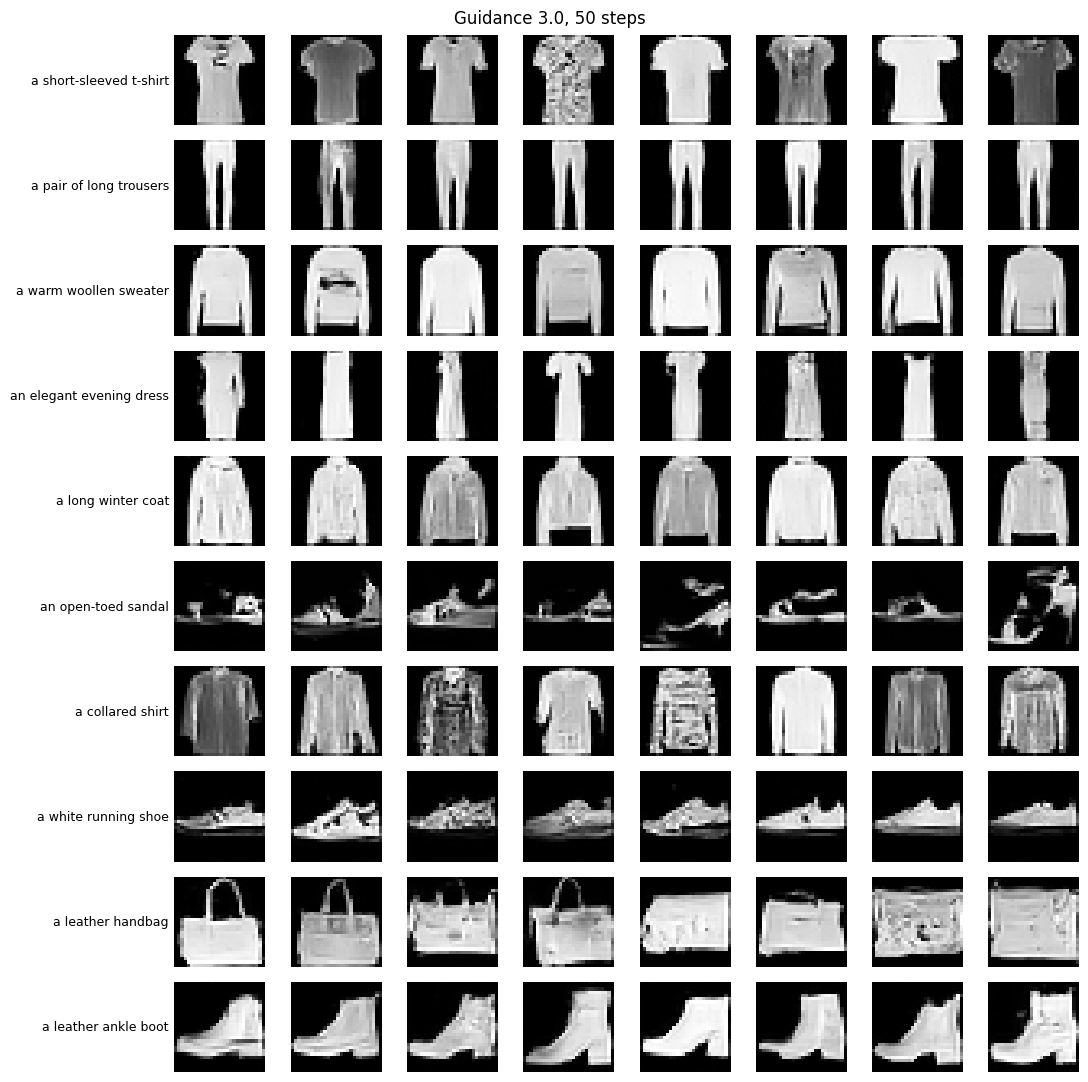

In [8]:
#@title ✍️ Draw every test prompt
images = generate(TEST_PROMPTS, per_prompt=8)
show_grid(images, 10, 8, row_titles=TEST_PROMPTS, title=f"Guidance {GUIDANCE_SCALE}, {SAMPLING_STEPS} steps")

### Does the image match the prompt?

A small separate classifier is trained on the real images, then asked what each generated image shows. With guidance 0 the prompt is ignored, so matches are down to chance, about 10%. The gap between the two columns shows how much the prompt steers the model.

In [9]:
#@title 🎯 Measure how often the image matches the prompt
classifier = nn.Sequential(
    nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Linear(128, 10),
).to(DEVICE)
classifier_optimizer = torch.optim.Adam(classifier.parameters(), lr=1e-3)
for _ in range(3):
    for idx in torch.randperm(len(train_images), device=DEVICE).split(256):
        loss = F.cross_entropy(classifier(train_images[idx]), train_labels[idx])
        classifier_optimizer.zero_grad(set_to_none=True)
        loss.backward()
        classifier_optimizer.step()
classifier.eval()
with torch.no_grad():
    real_accuracy = (classifier(test_images).argmax(1) == test_labels).float().mean().item()
print(f"Classifier accuracy on real test images: {real_accuracy:.1%} (the upper limit for the scores below)\n")


@torch.no_grad()
def match_rate(guidance):
    rates = []
    for c, prompt in enumerate(TEST_PROMPTS):
        drawn = generate([prompt], per_prompt=EVAL_IMAGES_PER_PROMPT, guidance=guidance, seed=SEED + c)
        rates.append((classifier(drawn).argmax(1) == c).float().mean().item())
    return rates


guided, unguided = match_rate(GUIDANCE_SCALE), match_rate(0.0)
print(f"{'Prompt':28} {'guidance ' + str(GUIDANCE_SCALE):>14} {'guidance 0':>12}")
for prompt, g, u in zip(TEST_PROMPTS, guided, unguided):
    print(f"{prompt:28} {g:>14.0%} {u:>12.0%}")
print(f"{'Average':28} {sum(guided) / 10:>14.0%} {sum(unguided) / 10:>12.0%}")
print(f"\n{EVAL_IMAGES_PER_PROMPT} images per prompt.")

Classifier accuracy on real test images: 88.8% (the upper limit for the scores below)
Prompt                         guidance 3.0   guidance 0
a short-sleeved t-shirt                 98%          18%
a pair of long trousers                100%           3%
a warm woollen sweater                  99%          17%
an elegant evening dress               100%          15%
a long winter coat                      97%          12%
an open-toed sandal                    100%           9%
a collared shirt                        85%           4%
a white running shoe                   100%          14%
a leather handbag                      100%          12%
a leather ankle boot                   100%           4%
Average                                 98%          11%
100 images per prompt.


### From noise to clothing

One image at selected sampling steps: the model starts from pure noise and removes a little at each step.

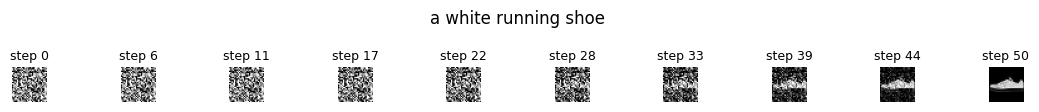

In [10]:
#@title 🌫️ Watch one image form
frames = []
generate(["a white running shoe"], per_prompt=1, record=frames)
picks = [round(i * (len(frames) - 1) / 9) for i in range(10)]
show_grid(torch.cat([frames[i] for i in picks]), 1, 10, col_titles=[f"step {i}" for i in picks],
          title="a white running shoe")

### What guidance does

The same prompt and starting noise at four guidance scales. At 0 the prompt is ignored. Higher values follow the prompt more strongly, and very high values can look less natural.

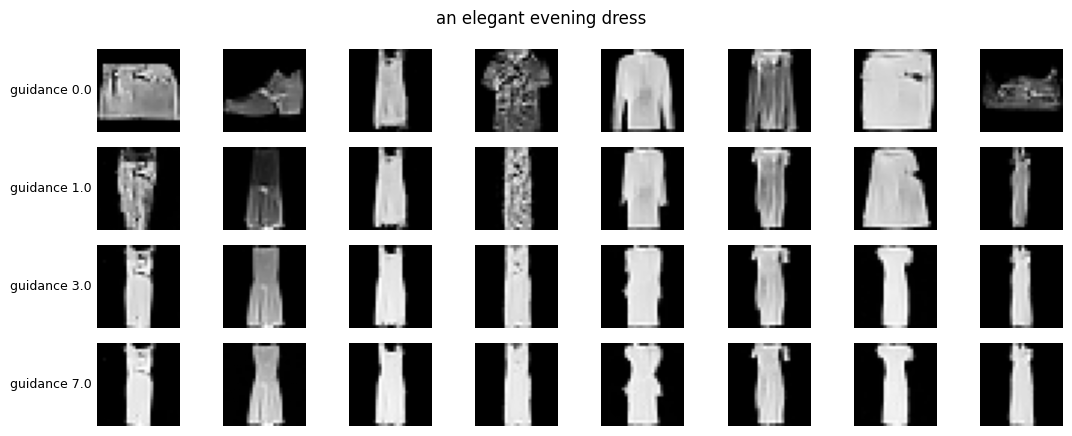

In [11]:
#@title 🎚️ Compare guidance scales
scales = [0.0, 1.0, 3.0, 7.0]
rows = [generate(["an elegant evening dress"], per_prompt=8, guidance=s) for s in scales]
show_grid(torch.cat(rows), len(scales), 8, row_titles=[f"guidance {s}" for s in scales],
          title="an elegant evening dress")

### Try your own prompts

Change the list and run the cell again. Prompts that are not close enough to one of the 10 categories, such as "a cat", are reported, not drawn.

The check is approximate: it compares CLIP's numbers for the prompt with each category, and the gap between real and off-topic prompts is small. Prompts near the threshold, printed in section 2, can be misjudged either way.

'a thick jacket': closest category Coat (similarity 0.929)
'a stylish shoe': closest category Sneaker (similarity 0.926)
'a nice bag': closest category Bag (similarity 0.945)


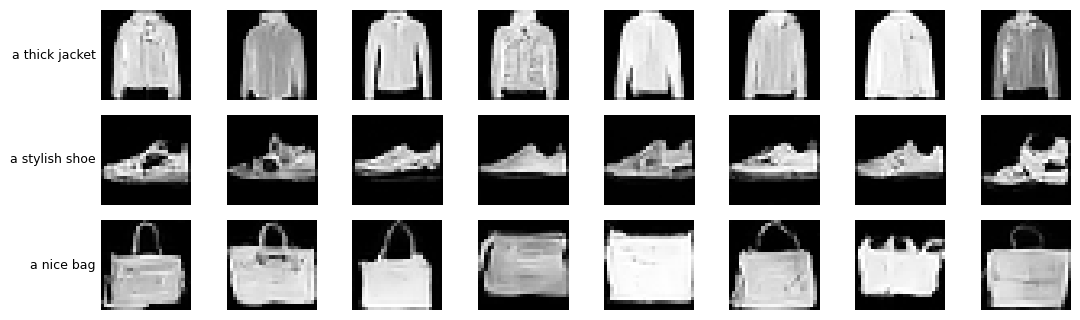

In [15]:
#@title ✏️ Your own prompts
MY_PROMPTS = ["a thick jacket", "a stylish shoe", "a nice bag"]

scores, matches = closest_category(MY_PROMPTS)
known = []
for text, score, match in zip(MY_PROMPTS, scores, matches):
    if score >= KNOWN_THRESHOLD:
        known.append(text)
        print(f"{text!r}: closest category {CLASS_NAMES[match]} (similarity {score:.3f})")
    else:
        print(f"{text!r}: not one of the 10 categories this model knows (similarity {score:.3f}), so it is not drawn")
if known:
    show_grid(generate(known, per_prompt=8), len(known), 8, row_titles=known)

## Tips

- **A first test:** tick `QUICK_CHECK` in Settings. Every cell runs in a few minutes, but the images stay noisy.
- **Better images:** raise `EPOCHS`, for example to 40, which roughly doubles the training time.
- **Guidance:** `GUIDANCE_SCALE` around 2–4 usually balances matching the prompt and looking natural.
- **Speed:** the training cell prints steps per second and the time left after every epoch, so the first epoch shows how long the full run will take.
- **Limits:** the model knows only the 10 Fashion-MNIST categories. It cannot draw colour, patterns, or anything outside those categories.